![Tutorial_banner](images/cbens_2026_performancetutorial_logo.jpg)

# Tutorial complementar — Dados meteorológicos para modelagem fotovoltaica
### Acesso, interpretação, visualização e preparação de dados com Python e pvlib

**CBENS · PV Performance Modeling in Practice**

Primeiro demonstramos como obter dados solares por API; depois trabalhamos com **um arquivo NSRDB já disponibilizado**. Não é necessário baixar nada durante a aula.

**Objetivos:** distinguir dados históricos e TMY; reconhecer GHI, DNI, DHI, temperatura ambiente e vento; explorar metadados, horários e unidades; visualizar séries; agregar irradiância em energia; comparar fontes; preparar entradas consistentes para modelos de desempenho.

> **Dados necessários:** `weather_data/nsrdb_33.6762_-83.67633_nsrdb-GOES-aggregated-v4-0-0_60_2016.csv`. As imagens históricas do tutorial de referência são opcionais e estão listadas no README de recursos.


## Roteiro

**Parte A — Download rápido (opcional):** configuração da API, série histórica de 60 minutos e alternativa de 15 minutos para anos disponíveis.

**Parte B — Tutorial de dados meteorológicos:**
1. Por que dados meteorológicos são importantes no desempenho FV?
2. Histórico observado/estimado × Ano Meteorológico Típico (TMY)
3. Ler dados, explorar metadados e validar índices temporais
4. Entender irradiância (GHI, DNI, DHI), temperatura e vento
5. Visualizar, selecionar períodos e comparar estações
6. Irradiância × irradiação: médias e integração em energia
7. Fontes de dados e qualidade para validação em campo
8. Exercícios e conexão com a simulação da usina

## Parte A — Download rápido de dados NSRDB (opcional)

A [NSRDB](https://nsrdb.nlr.gov/) oferece dados meteorológicos e de irradiância derivados principalmente de satélite e modelos atmosféricos. Com `pvlib.iotools`, podemos solicitar dados por localização e ano.

- **GOES Aggregated v4:** 30 ou 60 minutos; aqui usamos **60 minutos** para corresponder ao exercício principal.
- **GOES CONUS v4:** permite 5, 15, 30 ou 60 minutos para anos cobertos (por exemplo, 2023); exemplo de **15 minutos** abaixo.
- **`DEMO_KEY`** é apenas para demonstração, com limites severos. Para downloads confiáveis, obtenha uma chave gratuita em [NLR Developer Network](https://developer.nlr.gov/signup/).

**Atenção:** as duas solicitações são independentes, não fazem interpolação e podem falhar por limites da API. A seção principal usa um CSV local, sem internet.

In [1]:
# Instalação (descomente no Colab, caso necessário)
# %pip install pvlib pandas matplotlib

import pvlib
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

print('Versão pvlib:', pvlib.__version__)

Versão pvlib: 0.16.1


In [4]:
# Credenciais para demonstração — substitua por chave pessoal se necessário
API_KEY = 'DEMO_KEY'
EMAIL = 'seu_email@exemplo.com'  # TODO: use um e-mail válido
LATITUDE = 33.6762
LONGITUDE = -83.67633

# Mantenha False na aula se o CSV já foi fornecido.
EXECUTAR_DOWNLOADS = False

### A1. Solicitar o arquivo horário equivalente ao do exercício (60 minutos)

No nosso exercício principal, o ano de **2016** foi obtido do produto NSRDB GOES Aggregated v4. A função seguinte retorna uma série temporal (`DataFrame`) e um dicionário de metadados. O nome do CSV salvo é apenas uma convenção local.

In [5]:
if EXECUTAR_DOWNLOADS:
    nsrdb_60, meta_60 = pvlib.iotools.get_nsrdb_psm4_aggregated(
        latitude=LATITUDE,
        longitude=LONGITUDE,
        api_key=API_KEY,
        email=EMAIL,
        year=2016,
        time_step=60,
        map_variables=True,
        leap_day=True,
    )
    display(nsrdb_60.head())
    print('Registros:', len(nsrdb_60))
    Path('weather_data').mkdir(exist_ok=True)
    nsrdb_60.to_csv('weather_data/Simon_Solar_2016_60min_download.csv',
                    index_label='timestamp')

,Year,Month,Day,Hour,Minute,temp_air,temp_dew,dhi,dni,ghi,albedo,pressure,wind_direction,wind_speed
2016-01-01 00:30:00-05:00,2016,1,1,0,30,8.8,7.9,0.0,0.0,0.0,0.12,992.0,305.0,0.5
2016-01-01 01:30:00-05:00,2016,1,1,1,30,8.3,7.6,0.0,0.0,0.0,0.12,992.0,305.0,0.5
2016-01-01 02:30:00-05:00,2016,1,1,2,30,7.7,7.2,0.0,0.0,0.0,0.12,992.0,310.0,0.5
2016-01-01 03:30:00-05:00,2016,1,1,3,30,7.0,6.8,0.0,0.0,0.0,0.12,992.0,313.0,0.5
2016-01-01 04:30:00-05:00,2016,1,1,4,30,6.3,6.2,0.0,0.0,0.0,0.12,992.0,317.0,0.5


Registros: 8784


### A2. Solicitar dados de maior resolução (15 minutos)

A opção de 15 minutos é de **outro produto**: GOES CONUS v4, com dados disponíveis a partir de **2018**. Compare os produtos e a cobertura temporal antes de misturar as séries. Dados sub-horários podem oferecer variações que uma série horária não representa; **interpolar dados horários não cria observações de 15 minutos**.

In [24]:
if EXECUTAR_DOWNLOADS:
    nsrdb_15, meta_15 = pvlib.iotools.get_nsrdb_psm4_conus(
        latitude=LATITUDE,
        longitude=LONGITUDE,
        api_key=API_KEY,
        email=EMAIL,
        year=2018,               # ano disponível no CONUS v4
        time_step=15,
        map_variables=True,
        leap_day=True,
    )
    print('Intervalo típico:', nsrdb_15.index.to_series().diff().median())
    display(nsrdb_15.head())
    nsrdb_15.to_csv('weather_data/Simon_Solar_2018_15min_download.csv',
                    index_label='timestamp')

Intervalo típico: 0 days 00:15:00


,Year,Month,Day,Hour,Minute,temp_air,temp_dew,dhi,dni,ghi,albedo,pressure,wind_direction,wind_speed
2018-01-01 00:00:00-05:00,2018,1,1,0,0,-3.7,-7.6,0.0,0.0,0.0,0.12,997.0,337.0,0.5
2018-01-01 00:15:00-05:00,2018,1,1,0,15,-3.6,-7.6,0.0,0.0,0.0,0.12,997.0,341.0,0.5
2018-01-01 00:30:00-05:00,2018,1,1,0,30,-3.5,-7.6,0.0,0.0,0.0,0.12,997.0,344.0,0.6
2018-01-01 00:45:00-05:00,2018,1,1,0,45,-3.3,-7.6,0.0,0.0,0.0,0.12,997.0,348.0,0.6
2018-01-01 01:00:00-05:00,2018,1,1,1,0,-3.2,-7.6,0.0,0.0,0.0,0.12,997.0,352.0,0.7


---
# Parte B — Entendendo os dados meteorológicos
## 1. Dados meteorológicos e desempenho fotovoltaico

A produção de um sistema FV depende principalmente da **irradiância incidente**, mas também da temperatura das células e das condições de ventilação. Os dados podem vir de **instrumentos em campo**, de **modelos derivados de satélite**, de **reanálises** ou de produtos que combinam diferentes fontes.

O dado meteorológico não é uma medição de produção FV; ele é **uma entrada do modelo**. Na validação, precisamos distinguir erro de previsão meteorológica, erro de parâmetros do sistema e comportamento real em campo.

![Estação de medição](images/A1_SRRL.PNG)

## 2. Histórico de um ano × TMY

Um **ano histórico** contém uma sequência cronológica para um ano específico (por exemplo, 2016), apropriada para comparar com a energia realmente produzida naquele ano.

Um **Ano Meteorológico Típico (TMY)** é construído escolhendo meses representativos de uma série de vários anos, conforme critérios estatísticos. É útil para estimativas típicas de longo prazo, **mas não deve ser usado como se fosse a meteorologia real de 2016**. Nem sempre é o ano de irradiação exatamente mediana: a seleção também pode considerar outras variáveis e critérios.

Exemplo de dados meteorológicos e metadados no formato TMY3, antecessor dos formatos PSM utilizados atualmente pelo NSRDB. O TMY3 é um formato legado, mas ainda pode ser encontrado em bases de dados históricas.

![Estação de medição](images/A1_tmy3_example.PNG)

**Pergunta:** em que situações você escolheria um TMY e em quais precisaria de um ano histórico específico?

## 3. Abrir o arquivo NSRDB local

Arquivos originais NSRDB PSM4 em formato CSV/SAM incluem **metadados** e dados horários. Usaremos [`pvlib.iotools.read_nsrdb_psm4`](https://pvlib-python.readthedocs.io/en/stable/reference/generated/pvlib.iotools.read_nsrdb_psm4.html) para ler a estrutura original sem perder o cabeçalho.


In [8]:
weather_file = Path('weather_data') / ('nsrdb_33.6762_-83.67633_nsrdb-GOES-aggregated-v4-0-0_60_2016.csv')

weather, weather_meta = pvlib.iotools.read_nsrdb_psm4(weather_file, map_variables=True)

print('Número de registros:', len(weather))
print('Período:', weather.index.min(), 'até', weather.index.max())
print('Colunas:', list(weather.columns))
display(weather.head())

Número de registros: 8760
Período: 2016-01-01 00:30:00-05:00 até 2016-12-31 23:30:00-05:00
Colunas: ['Year', 'Month', 'Day', 'Hour', 'Minute', 'temp_air', 'Alpha', 'Aerosol Optical Depth', 'Asymmetry', 'dhi_clear', 'dni_clear', 'ghi_clear', 'Cloud Fill Flag', 'Cloud Type', 'temp_dew', 'dhi', 'dni', 'Fill Flag', 'ghi', 'Ozone', 'relative_humidity', 'solar_zenith', 'SSA', 'albedo', 'pressure', 'precipitable_water', 'wind_direction', 'wind_speed', 'Global Horizontal UV Irradiance (280-400nm)', 'Global Horizontal UV Irradiance (295-385nm)']


,Year,Month,Day,Hour,Minute,temp_air,Alpha,Aerosol Optical Depth,Asymmetry,dhi_clear,...,relative_humidity,solar_zenith,SSA,albedo,pressure,precipitable_water,wind_direction,wind_speed,Global Horizontal UV Irradiance (280-400nm),Global Horizontal UV Irradiance (295-385nm)
2016-01-01 00:30:00-05:00,2016,1,1,0,30,8.8,1.32,0.049,0.62,0.0,...,94.19,169.21,0.95,0.12,992.0,1.8,305.0,0.5,0.0,0.0
2016-01-01 01:30:00-05:00,2016,1,1,1,30,8.3,1.31,0.048,0.62,0.0,...,95.05,164.37,0.95,0.12,992.0,1.8,305.0,0.5,0.0,0.0
2016-01-01 02:30:00-05:00,2016,1,1,2,30,7.7,1.33,0.046,0.62,0.0,...,96.71,153.24,0.95,0.12,992.0,1.7,310.0,0.5,0.0,0.0
2016-01-01 03:30:00-05:00,2016,1,1,3,30,7.0,1.36,0.043,0.62,0.0,...,98.49,140.97,0.94,0.12,992.0,1.4,313.0,0.5,0.0,0.0
2016-01-01 04:30:00-05:00,2016,1,1,4,30,6.3,1.38,0.042,0.62,0.0,...,99.30,128.50,0.94,0.12,992.0,1.3,317.0,0.5,0.0,0.0


### Metadados, `DataFrame` e resolução temporal

- `weather` contém **uma linha por instante**, com colunas para variáveis meteorológicas.
- `weather_meta` descreve a localização, origem e outras informações do arquivo.
- `weather.index` é o índice de tempo. Confira **fuso horário e convenção de timestamp** antes de relacionar meteorologia, posição solar e potência medida.

As séries NSRDB podem usar **horário local padrão sem horário de verão**. Não assuma que timestamps de PVDAQ, de arquivos exportados ou de inversores compartilham o mesmo fuso. Também precisamos saber se o horário identifica o começo, meio ou fim do intervalo.

In [9]:
display(weather_meta)
print('Formato do índice:', type(weather.index))
print('Fuso:', weather.index.tz)
print('Intervalo típico:', weather.index.to_series().diff().median())
print('Colunas:', len(weather.columns))
print('Duplicatas:', weather.index.duplicated().sum())
print('Valores ausentes (principais):')
display(weather[['ghi','dni','dhi','temp_air','wind_speed']].isna().sum())

{'Source': 'NSRDB',
 'Location ID': '985762',
 'City': '-',
 'State': '-',
 'Country': '-',
 'Time Zone': -5,
 'Local Time Zone': -5,
 'Clearsky DHI Units': 'w/m2',
 'Clearsky DNI Units': 'w/m2',
 'Clearsky GHI Units': 'w/m2',
 'Dew Point Units': 'c',
 'DHI Units': 'w/m2',
 'DNI Units': 'w/m2',
 'GHI Units': 'w/m2',
 'Solar Zenith Angle Units': 'Degree',
 'Temperature Units': 'c',
 'Pressure Units': 'mbar',
 'Relative Humidity Units': '%',
 'Precipitable Water Units': 'cm',
 'Wind Direction Units': 'Degrees',
 'Wind Speed Units': 'm/s',
 'Cloud Type -15': '',
 'Cloud Type 0': 'Clear',
 'Cloud Type 1': 'Probably Clear',
 'Cloud Type 2': 'Fog',
 'Cloud Type 3': 'Water',
 'Cloud Type 4': 'Super-Cooled Water',
 'Cloud Type 5': 'Mixed',
 'Cloud Type 6': 'Opaque Ice',
 'Cloud Type 7': 'Cirrus',
 'Cloud Type 8': 'Overlapping',
 'Cloud Type 9': 'Overshooting',
 'Cloud Type 10': 'Unknown',
 'Cloud Type 11': 'Dust',
 'Cloud Type 12': 'Smoke',
 'Fill Flag 0': '',
 'Fill Flag 1': 'Missing Image',


Formato do índice: <class 'pandas.core.indexes.datetimes.DatetimeIndex'>
Fuso: Etc/GMT+5
Intervalo típico: 0 days 01:00:00
Colunas: 30
Duplicatas: 0
Valores ausentes (principais):


ghi           0
dni           0
dhi           0
temp_air      0
wind_speed    0
dtype: int64

## 4. Variáveis que utilizaremos no modelo

| Variável pvlib | Significado | Unidade usual |
|---|---|---|
| `ghi` | Irradiância global horizontal | W/m² |
| `dni` | Irradiância direta normal ao Sol | W/m² |
| `dhi` | Irradiância difusa horizontal | W/m² |
| `temp_air` | Temperatura ambiente (*dry-bulb*) | °C |
| `wind_speed` | Velocidade do vento | m/s |

**GHI não é simplesmente DNI + DHI.** Em uma superfície horizontal, uma relação aproximada é: **GHI = DNI × cos(ângulo zenital) + DHI**, quando a geometria e os dados são consistentes.

![DNI DHI GHIo](images/A1_DNIDHIGHI.PNG)

O DNI mede a radiação direta em um plano **normal aos raios solares**; o DHI mede a radiação difusa sobre um plano **horizontal**. As figuras embaixo ajudam a visualisar essa distinção. 


![DNI DHI GHIo](images/A1_GHI.PNG)
![DNI DHI GHIo](images/A1_DNI.PNG)
![DNI DHI GHIo](images/A1_DHI.PNG)



In [11]:
# Selecionar as variáveis principais em um DataFrame menor
colunas = ['ghi', 'dni', 'dhi', 'temp_air', 'wind_speed']
df = weather[colunas].copy()
display(df.head(15))
print('Nomes de colunas:', list(df.columns))

,ghi,dni,dhi,temp_air,wind_speed
2016-01-01 00:30:00-05:00,0.0,0.0,0.0,8.8,0.5
2016-01-01 01:30:00-05:00,0.0,0.0,0.0,8.3,0.5
2016-01-01 02:30:00-05:00,0.0,0.0,0.0,7.7,0.5
2016-01-01 03:30:00-05:00,0.0,0.0,0.0,7.0,0.5
2016-01-01 04:30:00-05:00,0.0,0.0,0.0,6.3,0.5
2016-01-01 05:30:00-05:00,0.0,0.0,0.0,5.9,0.5
2016-01-01 06:30:00-05:00,0.0,0.0,0.0,5.5,0.5
2016-01-01 07:30:00-05:00,0.0,0.0,0.0,5.5,0.6
2016-01-01 08:30:00-05:00,55.0,7.0,54.0,6.7,0.7
2016-01-01 09:30:00-05:00,189.0,116.0,153.0,8.6,0.7


Nomes de colunas: ['ghi', 'dni', 'dhi', 'temp_air', 'wind_speed']


### Temperatura e vento

A temperatura ambiente influencia a **temperatura da célula**; o vento ajuda a resfriar a superfície do módulo. Por isso, mesmo com a mesma irradiância, a potência pode mudar com o clima.

![Vento e Temperatura](images/A1_WindAnemometerAlbedoSensors.PNG)


## 5. Visualização de séries meteorológicas

Séries temporais tornam padrões e problemas de qualidade mais visíveis. Vamos comparar as três componentes de irradiância numa semana e depois selecionar um dia, preservando sua **resolução horária**.

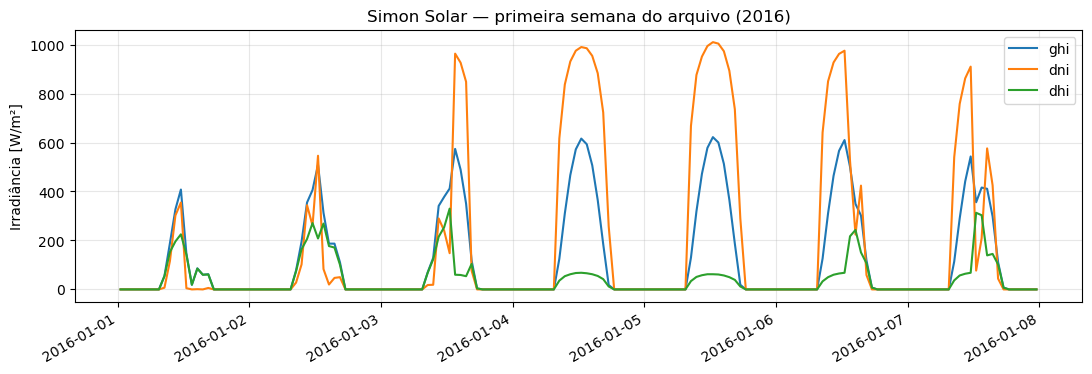

In [12]:
primeira_semana = df.iloc[:24*7]
primeira_semana[['ghi','dni','dhi']].plot(figsize=(13,4))
plt.ylabel('Irradiância [W/m²]')
plt.title('Simon Solar — primeira semana do arquivo (2016)')
plt.grid(alpha=0.3)
plt.show()

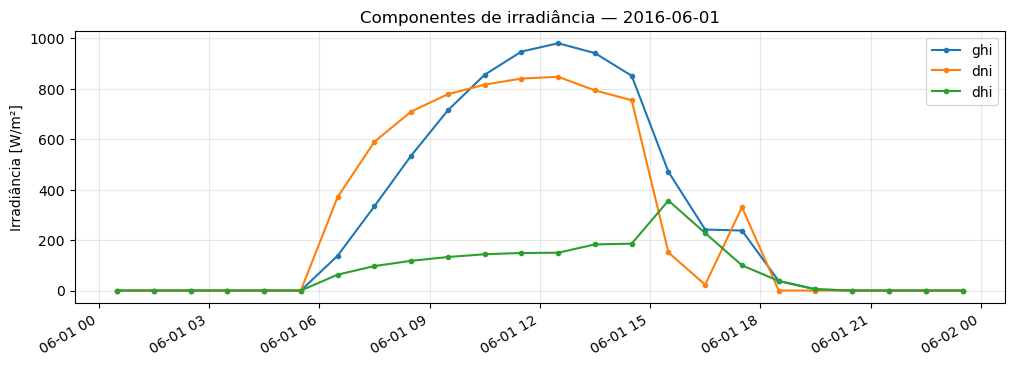

In [13]:
# TODO: escolha qualquer dia de 2016 para investigar
meu_dia = '2016-06-01'
dia = df.loc[meu_dia]

dia[['ghi','dni','dhi']].plot(figsize=(12,4), marker='.')
plt.ylabel('Irradiância [W/m²]')
plt.title(f'Componentes de irradiância — {meu_dia}')
plt.grid(alpha=0.3)
plt.show()

**Exercício:** escolha a data do seu aniversário em 2016. Qual componente é mais sensível à passagem de nuvens? Em um dia nublado, o DNI sempre é maior que o DHI?

> Atenção: comparar magnitudes de DNI e DHI exige lembrar que seus planos de referência são diferentes.

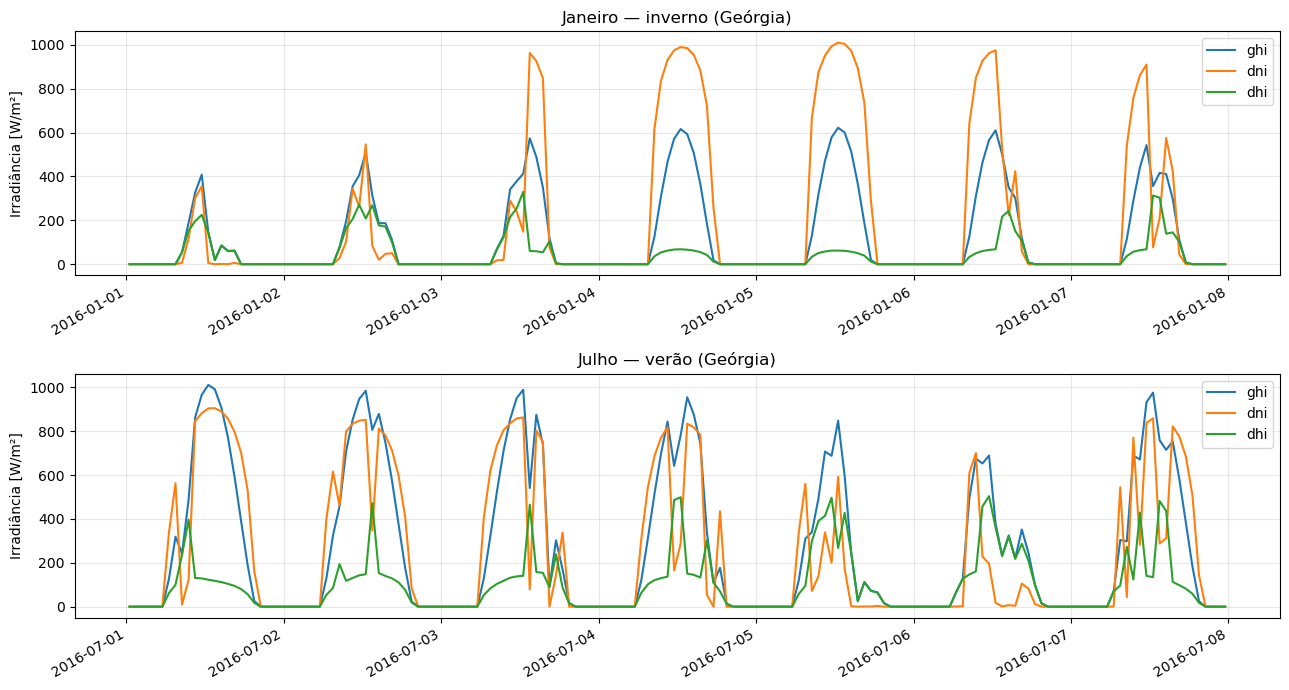

In [14]:
# Comparar semanas de verão e inverno no hemisfério norte
inverno = df.loc['2016-01-01':'2016-01-07', ['ghi','dni','dhi']]
verao = df.loc['2016-07-01':'2016-07-07', ['ghi','dni','dhi']]

fig, axes = plt.subplots(2, 1, figsize=(13,7), sharey=True)
inverno.plot(ax=axes[0], title='Janeiro — inverno (Geórgia)')
verao.plot(ax=axes[1], title='Julho — verão (Geórgia)')
for ax in axes:
    ax.set_ylabel('Irradiância [W/m²]')
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

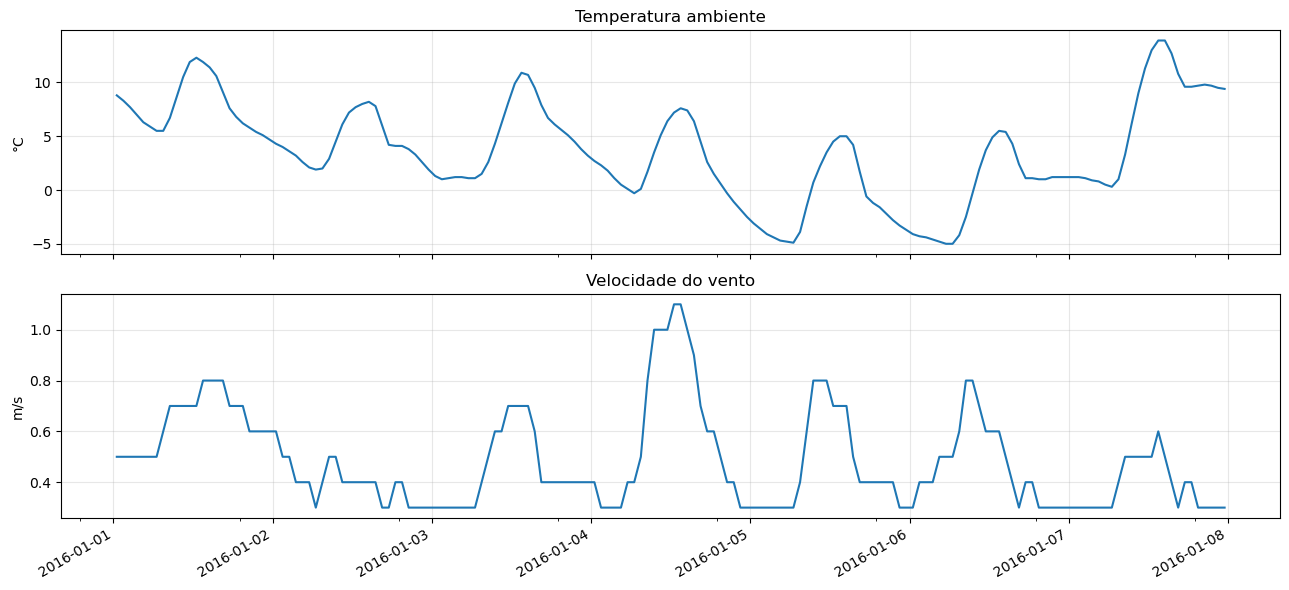

In [15]:
fig, axes = plt.subplots(2, 1, figsize=(13,6), sharex=True)
primeira_semana['temp_air'].plot(ax=axes[0], title='Temperatura ambiente')
primeira_semana['wind_speed'].plot(ax=axes[1], title='Velocidade do vento')
axes[0].set_ylabel('°C')
axes[1].set_ylabel('m/s')
for ax in axes: ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 6. Irradiância versus irradiação

- **Irradiância:** potência instantânea por área, em **W/m²**.
- **Irradiação:** energia acumulada por área durante um intervalo, em **Wh/m²** ou **kWh/m²**.

Para dados horários tratados como **valores médios de cada hora**, somar `GHI × 1 hora` estima a irradiação acumulada. Para 15 ou 30 minutos, é necessário multiplicar pela duração correta do intervalo. Não somamos irradiância diretamente quando a duração dos intervalos difere.

A integração abaixo é válida para a série horária **completa e regular** usada no exercício.

Intervalo (horas): 1.0


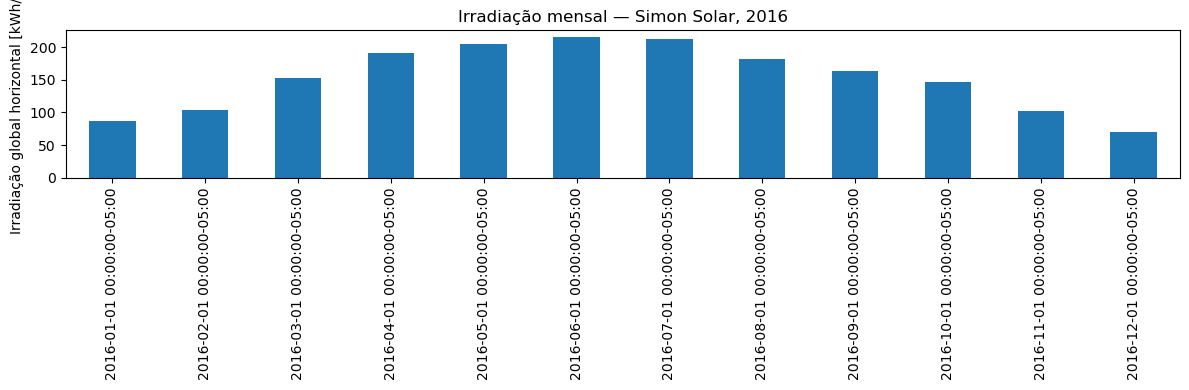

In [16]:
# Confirmar que a série é horária antes da integração
intervalo_h = df.index.to_series().diff().median() / pd.Timedelta(hours=1)
print('Intervalo (horas):', intervalo_h)
assert intervalo_h == 1, 'Este exemplo supõe dados horários.'

# Wh/m² -> kWh/m² por mês
irradiacao_mensal = (df['ghi'] * intervalo_h).resample('MS').sum() / 1000
irradiacao_mensal.plot.bar(figsize=(12,4))
plt.ylabel('Irradiação global horizontal [kWh/m²]')
plt.title('Irradiação mensal — Simon Solar, 2016')
plt.tight_layout()
plt.show()

### Médias e somas são perguntas diferentes

- **Temperatura e vento:** frequentemente queremos **médias mensais**.
- **Irradiação:** queremos **energia acumulada**, integrando a irradiância no tempo.
- **Irradiância média:** útil para comparar padrões, mas não tem a unidade de energia.

Para frequências mensais, `MS` marca o **início** do mês. Veja também [`pandas.DataFrame.resample`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.resample.html).

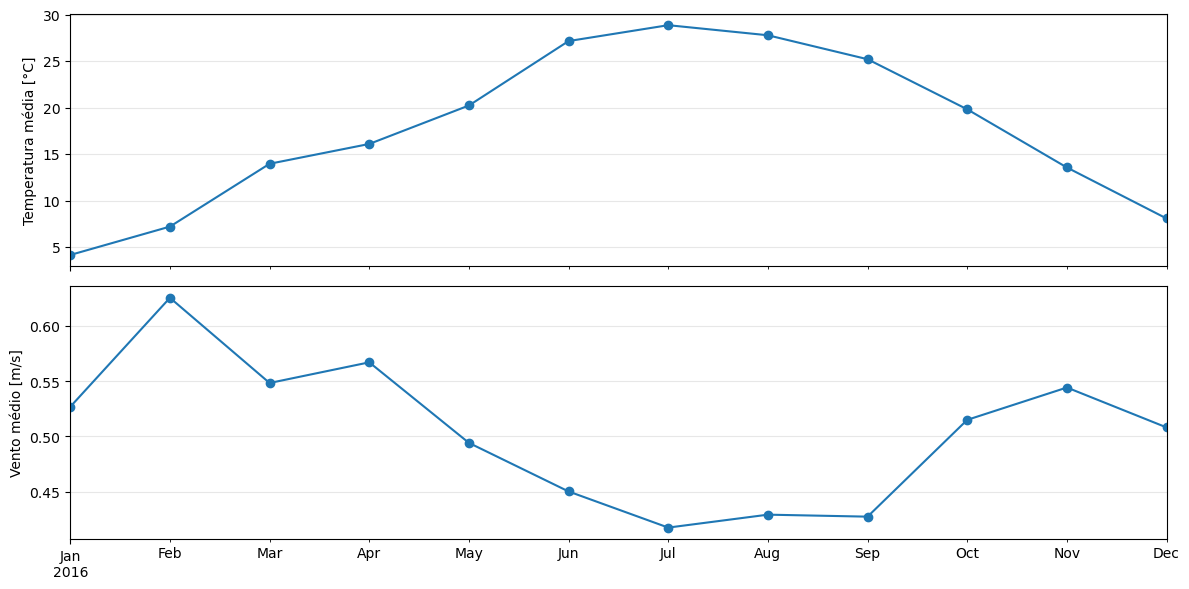

In [17]:
medias_mensais = df[['temp_air', 'wind_speed']].resample('MS').mean()

fig, axes = plt.subplots(2, 1, figsize=(12,6), sharex=True)
medias_mensais['temp_air'].plot(ax=axes[0], marker='o')
medias_mensais['wind_speed'].plot(ax=axes[1], marker='o')
axes[0].set_ylabel('Temperatura média [°C]')
axes[1].set_ylabel('Vento médio [m/s]')
for ax in axes: ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Exercício guiado:** calcule (a) o DNI médio diário em W/m² e (b) a irradiação direta normal diária em kWh/m². Qual é a diferença física entre os resultados?

In [ ]:
# TODO: completar frequências, operações e unidades
dni_medio_diario = df['dni'].resample(...).mean()
ird_dni_diaria = (df['dni'] * intervalo_h).resample(...).sum() / ...

# display(dni_medio_diario.head())
# display(ird_dni_diaria.head())

## 7. Onde encontrar dados meteorológicos e de irradiância?

**Fontes gratuitas e públicas (dependendo da cobertura e do produto):**

- [NSRDB](https://nsrdb.nlr.gov/) — séries históricas e TMY derivados de satélite/modelos, com acesso programático.
- [PVGIS](https://re.jrc.ec.europa.eu/pvg_tools/en/) — dados horários e TMY para diversas regiões.
- [NASA POWER](https://power.larc.nasa.gov/) — séries meteorológicas e solares globais para análise.
- [EPW/EnergyPlus](https://energyplus.net/weather) — arquivos meteorológicos de projeto, lidos com `pvlib.iotools.read_epw()`.
- [TMY2/TMY3](https://nsrdb.nlr.gov/data-sets/archives.html) — formatos e coleções históricas; hoje há produtos NSRDB mais recentes.

**Exemplos comerciais:** Solargis, SolarAnywhere, Meteonorm e serviços especializados de avaliação de recurso solar.

Cada fonte apresenta diferenças de **resolução temporal, resolução espacial, cobertura geográfica, período, metodologia, atualização e incerteza**. Não escolha apenas pelo nome do provedor.

![Vento e Temperatura](images/A1_NSRDB_example.PNG)


### API: o que significa e por que usamos?

Uma **API** (*Application Programming Interface*) permite solicitar dados por código. Em serviços web, enviamos parâmetros como latitude, longitude, ano e intervalo de tempo; o servidor devolve um arquivo ou resultado estruturado.

Neste notebook as funções `get_...` do `pvlib.iotools` **solicitam dados pela internet**, enquanto `read_...` **leem um arquivo que já temos**. Para um workshop, distribuir previamente um CSV ajuda a garantir que todos trabalhem com o mesmo conjunto e evita problemas com acesso ou limites da API.

Documentação: [pvlib — ferramentas de entrada e saída](https://pvlib-python.readthedocs.io/en/stable/reference/iotools.html).

## 8. Boas práticas antes de comparar meteorologia e desempenho medido

1. **Fuso horário e DST:** não confunda UTC, horário padrão local e horário de verão. Verifique o *significado do timestamp*.
2. **Resolução:** 1,5,10 ou 15 minutos versus 60 minutos requer agregação coerente e cobertura suficiente dos intervalos.
3. **Variáveis e unidades:** W/m² não é Wh/m²; °C não é K; m/s não é km/h.
4. **Dados faltantes, repetidos ou inconsistentes:** sinalize antes de calcular energia e métricas.
5. **Origem dos dados:** satélite/modelo e instrumento local podem divergir por nuvens, resolução espacial, posicionamento e sensores.
6. **Dados TMY versus histórico:** use meteorologia correspondente ao mesmo período para validação de campo quando puder.

**Discussão:** se o modelo superestima produção por uma hora, isso significa necessariamente que os parâmetros dos módulos estão incorretos? Que outras hipóteses devemos verificar?

In [20]:
# Checagens básicas, sem substituir um procedimento completo de QA/QC
checagens = pd.Series({
    'registros': len(df),
    'duplicatas': df.index.duplicated().sum(),
    'ausentes_ghi': df['ghi'].isna().sum(),
    'ghi_negativo': (df['ghi'] < 0).sum(),
    'dni_negativo': (df['dni'] < 0).sum(),
    'dhi_negativo': (df['dhi'] < 0).sum(),
})
display(checagens.to_frame('valor'))

,valor
registros,8760
duplicatas,0
ausentes_ghi,0
ghi_negativo,0
dni_negativo,0
dhi_negativo,0


**Para reflexão:** qual é a diferença entre uma usina real apresentando indisponibilidade de inversores e um modelo recebendo dados meteorológicos inadequados? As duas situações podem reduzir a concordância entre a potência simulada e a medida, mas por motivos diferentes.

### Referências
- [pvlib: dados meteorológicos](https://pvlib-python.readthedocs.io/en/stable/user_guide/modeling_topics/weather_data.html)
- [pvlib: NSRDB PSM4](https://pvlib-python.readthedocs.io/en/stable/reference/iotools.html)
- [NLR Developer Network — NSRDB](https://developer.nlr.gov/docs/solar/nsrdb/)
- [PVGIS](https://re.jrc.ec.europa.eu/pvg_tools/en/)
- [pandas resample](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.resample.html)
